## Tune a firmware PID

Loads the plant saved under `model/` and searches `Kp`, `Ki`, `Kd`. `method` in `config/config.yaml` selects `powell` or `pygad`. Both minimize the same simulated ISE. The plant path, setpoint waveform, and gain limits come from that file. This notebook does not identify a plant.

`allow_steady_state_error: false` keeps `Ki` high enough to hold every level, without going above the limit you set. `true` searches the whole `Ki` range and may leave a shelf.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import pidtune
import plantid

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent

setup = plantid.load_config(ROOT / "config" / "config.yaml", root=ROOT).tune
LEVELS = setup.levels
HOLD_S = setup.hold
PLANT = setup.plant
DT = setup.dt
DEAD_ZONE = setup.dead_zone
KP = setup.kp
KI = setup.ki
KD = setup.kd
WE = setup.we
ALLOW_STEADY_STATE_ERROR = setup.allow_steady_state_error
METHOD = setup.method
GENERATIONS = setup.generations
POPULATION = setup.population

In [5]:
plant = pidtune.load_plant(PLANT)
tuned = pidtune.tune(
    plant,
    levels=LEVELS,
    hold=HOLD_S,
    dt=DT,
    dead_zone=DEAD_ZONE,
    kp=KP,
    ki=KI,
    kd=KD,
    we=WE,
    allow_steady_state_error=ALLOW_STEADY_STATE_ERROR,
    method=METHOD,
    generations=GENERATIONS,
    population=POPULATION,
)
print(tuned)

Kp = 3.32   Ki = 3   Kd = 0.005091
ISE = 2.427e+04   |e|_end 1.844


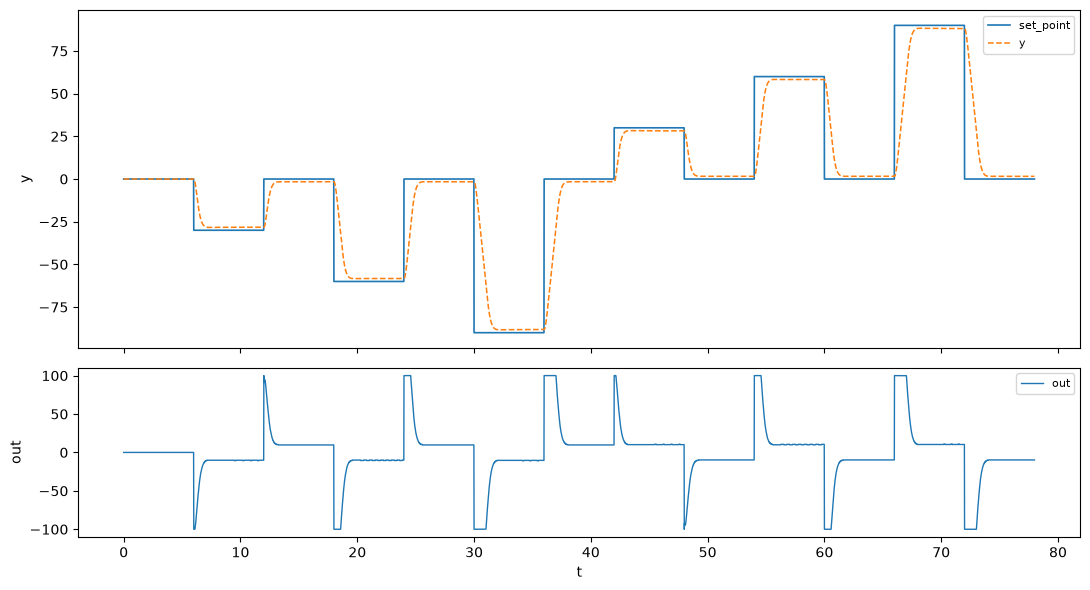

In [6]:
show_t = np.arange(len(tuned.reference)) * DT

fig, axes = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": (2, 1)}
)
axes[0].plot(show_t, tuned.reference, label="set_point", lw=1.2)
axes[0].plot(show_t, tuned.response, ls="--", label="y", lw=1.1)
axes[0].set_ylabel("y")
axes[0].legend(loc="best", fontsize=8)

axes[1].plot(show_t, tuned.output, label="out", lw=1.0)
axes[1].set_xlabel("t")
axes[1].set_ylabel("out")
axes[1].legend(loc="best", fontsize=8)
fig.tight_layout()